# Per-station overview (Alaska)

**Two pages per station** -- one for NISAR, one for Sentinel-1 -- each
pulling together everything this project has computed for that satellite:
NDVI/in-situ SM, De Zan coherence/closure-phase vs. in-situ SM (each track
with its own regression trend line), and the estimated-vs-in-situ SM
timeseries (SME2+NISAR, or S1 alone). A page is skipped entirely if that
satellite has no coherence/closure/estimate data at all for the station.
**A station is dropped entirely (no pages, no stats) if it has no in-situ
data at all** (currently just TurnagainPass) -- there's nothing to compare
against, so it contributed nothing but empty panels and NaN stats.

**Track colors and incidence angle live in one shared legend strip below
the 2x4 panel grid** (not a subtitle, not the scatter plots' own legend,
and not its own grid cell of mostly-empty whitespace) -- one swatch +
incidence angle per track, built from every track that appears anywhere
for that satellite (coherence, closure, or estimates), so a track never
silently disappears from the legend just because it happens to have no
scatter points. Both NISAR and S1 points are plotted as circles.

**"Good" tracks (Section 9's threshold-bootstrap criteria -- per-sensor
coherence/closure/NDVI thresholds derived from that sensor's own low-RMSE
tracks, see Section 9's "9c") are visually flagged wherever they appear**:
their legend entry is bold, and their dots in the coherence, closure-phase, and
estimate-timeseries panels all get a thick black outline (`GOOD_TRACK_EDGE_WIDTH`)
instead of the usual thin one -- computed once in Section 9, before the
per-station pages (Section 10) that use it.

**Tracks with dead coherence are dropped everywhere, including the
estimate-timeseries panel.** A track whose coherence-pair rows are *all*
NaN (every acquisition's saved GSLC window had its pixel mask flag the
whole window invalid) has no usable signal anywhere for that track --
coherence, closure phase, or a trustworthy SM estimate -- even though the
inversion output may still carry rows for it. `_tracks_with_dead_coherence`
excludes these from the legend, the estimate-timeseries scatter, and the
shared x-axis date range, rather than letting them appear ungrounded.

**Scatter-plot dot size is a significance signal, not a legend key**: in the
coherence panel, size scales with temporal baseline (shortest baseline =
biggest dot, longest = smallest-but-visible); in the closure-phase panel,
size scales with the triplet's minimum pairwise coherence (higher = bigger
dot). Both size scales are **fixed across every station/page** (baseline
against the global min/max seen anywhere in `stations_to_plot`, min-coherence
against its natural [0, 1] bound) -- not rescaled per page -- so the same
dot size always means the same underlying value. Each scatter panel's own
legend shows only that size-to-value mapping -- track identity is the
shared legend strip's job.

**Per-station, not fixed across stations**: axis ranges auto-scale to each
station's own data, except NDVI (0.2-1), coherence (0-1), and closure phase
(0-pi rad), which are always the same scale so panels are comparable at a
glance -- as is dot size (above). The NDVI panel and the estimate-timeseries
panel both plot Volumetric Soil Moisture (%) on their left axis, and that
axis is synced to the same range across *every* such panel for a station --
its NDVI panel(s) and both its NISAR and S1 estimate-timeseries panels all
share one y-range, computed after both pages are built, so a reader can
compare SM magnitude directly between a station's NISAR and S1 pages, not
just within one page. Track colors are only kept consistent *within* one
station's own pages, not across stations, and never reuse green -- reserved
for NDVI so a green track dot can't be mistaken for an NDVI point.

**In-situ gating**: an estimate, coherence pair, or closure triplet is only
plotted if every acquisition it depends on has a valid (gap-free) in-situ
interpolation at that date -- otherwise there's no SM difference/range to
compare it against. The estimate-timeseries x-axis is stretched to the
first/last *in-situ-covered* estimate across both satellites, +/- 24h.

**Depth: per-station pages (Section 10) output both 5cm and 20cm** -- a
station with both depths' data gets up to 4 pages (NISAR/S1 x 5cm/20cm).
Section 9's threshold-bootstrap and Section 11's pooled scatter plots run
at 5cm; Section 12 repeats just the scatter plots at 20cm (its screening
already happened in Section 9, alongside 5cm's). All points, **no
quality/fault filtering** on the in-situ series (this project's
`read_insitu` no longer does any). NDVI and in-situ SM are plotted as
points only, never interpolated/connected.

**Figure size: 15x9 in (~10:6), one slide each** for the per-station pages
-- sized to drop straight into a Google Slides deck without further
cropping.

**Data sources** (all precomputed by other notebooks in this project -- this
notebook only reads and plots, no new computation except station terrain):
- In-situ SM: `ismn_data/alaska/station_data/{station}_ts_0.05.csv` (5cm) /
  `_ts_0.20.csv` (20cm)
- NDVI: `nisar_data/alaska_HLS_ndvi/{station}_HLS_ndvi.csv`
- NISAR coherence/closure: `nisar_data/alaska_GSLC_coherence_closure/{station}_NISAR_GSLC_*.csv`
- Sentinel-1 coherence/closure: `S1_coherence_closure_alaska/{station}_orbit*_S1_*.csv`
- SME2: `SME2_data_alaska/sme2_cache.csv`
- NISAR/S1 SM estimates: `nisar_data/alaska_NISAR_SM_estimates.csv` / `S1_SM_estimates_alaska.csv`
  (written by the export cell at the end of `NISAR_SM_alaska.ipynb` /
  `S1_SM_alaska.ipynb` -- **re-run those two notebooks first** if you want
  this page to reflect a fresh inversion run)
- Station terrain (slope): computed here directly from Copernicus GLO-30,
  the same way `Earsel26_NISAR-main/util/nisar_station_timeseries.py`'s
  `compute_station_terrain` does for the GCOV backscatter pipeline -- no
  Earthdata credentials needed, just public DEM tiles.

In [1]:
import sys
import os
from pathlib import Path

import pyproj
pyproj.datadir.set_data_dir(os.path.join(sys.prefix, "Library", "share", "proj"))


def require_globals(*names):
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError(
            f"Missing {missing} -- run the earlier setup cells first "
            "(the kernel may have been restarted)."
        )


BASE = Path.cwd()
EARSEL_NOTEBOOKS = BASE / "Earsel26_NISAR-main" / "notebooks"
EARSEL_ROOT = EARSEL_NOTEBOOKS.parent
if str(EARSEL_ROOT) not in sys.path:
    sys.path.append(str(EARSEL_ROOT))

COH_CLOSURE_DIR = EARSEL_NOTEBOOKS / "nisar_data" / "alaska_GSLC_coherence_closure"
NDVI_DIR = EARSEL_NOTEBOOKS / "nisar_data" / "alaska_HLS_ndvi"
INSITU_DIR = EARSEL_NOTEBOOKS / "ismn_data" / "alaska" / "station_data"
S1_COH_CLOSURE_DIR = BASE / "S1_coherence_closure_alaska"
SME2_CACHE_PATH = BASE / "SME2_data_alaska" / "sme2_cache.csv"
NISAR_SM_ESTIMATES_PATH = EARSEL_NOTEBOOKS / "nisar_data" / "alaska_NISAR_SM_estimates.csv"
S1_SM_ESTIMATES_PATH = BASE / "S1_SM_estimates_alaska.csv"

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D

DATE_FORMATTER = mdates.DateFormatter("%b %d")

DEPTH_MAIN = 0.05
DEPTH_SECONDARY = 0.20
MAX_GAP_HOURS = 6
# Same safeguard Checks_alaska.ipynb/Checks_alaska_S1.ipynb use: a same-pass
# adjacent-frame pair/triplet leg can have a temporal baseline of seconds,
# which would otherwise show up as a near-zero-dSM point that's structurally
# guaranteed to look uninformative, not a real test of anything.
MIN_BASELINE_DAYS = 0.01

SENSOR_MARKER = {"NISAR": "o", "S1": "o"}
SIZE_MIN = 12
SIZE_MAX = 160
ALPHA_DOTS = 0.7
ALPHA_LEGEND = 0.75

FONT_SUPTITLE = 18
FONT_PANEL_TITLE = 13
FONT_AXIS_LABEL = 12
FONT_TICK = 11
FONT_LEGEND = 11

# Section 11/12's pooled scatter plots use their own, +2pt-larger font sizes --
# they're a different kind of figure (3-panel, one-off summary) from the
# per-station pages, not meant to match them.
FONT_SUPTITLE_SCATTER = FONT_SUPTITLE + 2
FONT_PANEL_TITLE_SCATTER = FONT_PANEL_TITLE + 2
FONT_AXIS_LABEL_SCATTER = FONT_AXIS_LABEL + 2
FONT_TICK_SCATTER = FONT_TICK + 2
FONT_LEGEND_SCATTER = FONT_LEGEND + 2

# tab10 with green (index 2) dropped -- reserved for NDVI, see build_track_color_map
TRACK_COLOR_PALETTE = [c for i, c in enumerate(plt.cm.tab10(np.linspace(0, 1, 10))) if i != 2]

# Dot outline for a "good" track (Section 9's threshold-bootstrap criteria), in both the
# estimate-timeseries panel and the coherence/closure-phase scatter panels
GOOD_TRACK_EDGE_COLOR = "black"
GOOD_TRACK_EDGE_WIDTH = 2.2
GOOD_TRACK_EDGE_WIDTH_ANCHOR = 2.6

# Per-station estimate-timeseries dot size, matched to the biggest possible dot in the
# coherence/closure scatter panels (SIZE_MAX) rather than its own small fixed size
ESTIMATE_DOT_SIZE = SIZE_MAX
ESTIMATE_ANCHOR_SIZE = SIZE_MAX + 60


C:\Users\geoka\miniconda3\envs\nisar-era5\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


## 1. Station list

In [2]:
require_globals("EARSEL_NOTEBOOKS")

stations_path = EARSEL_NOTEBOOKS / "ismn_data" / "alaska" / "stations.geojson"
with open(stations_path) as f:
    stations_geojson = json.load(f)

stations = {
    feat["properties"]["station_val"]: (
        feat["geometry"]["coordinates"][1],  # lat
        feat["geometry"]["coordinates"][0],  # lon
    )
    for feat in stations_geojson["features"]
}
print(f"Loaded {len(stations)} stations")


Loaded 20 stations


## 2. Data readers

Every reader returns `None` (or an empty DataFrame) when a station has no
file for that source -- every plot function below handles that by simply
leaving its panel empty, not by raising.

In [3]:
require_globals("INSITU_DIR", "NDVI_DIR", "COH_CLOSURE_DIR", "S1_COH_CLOSURE_DIR")


def read_insitu(station, depth=DEPTH_MAIN):
    path = INSITU_DIR / f"{station}_ts_{depth:.2f}.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    return df.iloc[:, 0].sort_index()  # single sm_<depth> column, whatever it's named


def interp_insitu_at(series, ts):
    before = series.loc[:ts]
    after = series.loc[ts:]
    if before.empty or after.empty:
        return np.nan
    t0, v0 = before.index[-1], before.iloc[-1]
    t1, v1 = after.index[0], after.iloc[0]
    if t0 == t1:
        return float(v0)
    gap_hours = (t1 - t0).total_seconds() / 3600.0
    if gap_hours > MAX_GAP_HOURS:
        return np.nan
    frac = (ts - t0).total_seconds() / (t1 - t0).total_seconds()
    return float(v0 + frac * (v1 - v0))


def _sm_diff_pct(df, series, col_a, col_b):
    a = df[col_a].apply(lambda ts: interp_insitu_at(series, ts))
    b = df[col_b].apply(lambda ts: interp_insitu_at(series, ts))
    return (a - b).abs() * 100


def _sm_range_pct(df, series, cols):
    vals = pd.concat([df[c].apply(lambda ts: interp_insitu_at(series, ts)) for c in cols], axis=1)
    return (vals.max(axis=1, skipna=False) - vals.min(axis=1, skipna=False)) * 100


def read_ndvi(station):
    path = NDVI_DIR / f"{station}_HLS_ndvi.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, parse_dates=["target_date"])
    df = df[df["n_valid_px"] > 0]
    if df.empty:
        return None
    return df.set_index("target_date")["ndvi_mean"].sort_index()


def read_nisar_coherence(station):
    path = COH_CLOSURE_DIR / f"{station}_NISAR_GSLC_coherence.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, parse_dates=["date_1", "date_2"])
    return df[df["temporal_baseline_days"] >= MIN_BASELINE_DAYS].copy()


def read_nisar_closure(station):
    path = COH_CLOSURE_DIR / f"{station}_NISAR_GSLC_closure_phase.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, parse_dates=["date_1", "date_2", "date_3"])
    keep = (
        (df["temporal_baseline_12_days"] >= MIN_BASELINE_DAYS)
        & (df["temporal_baseline_23_days"] >= MIN_BASELINE_DAYS)
        & (df["temporal_baseline_13_days"] >= MIN_BASELINE_DAYS)
    )
    return df[keep].copy()


def read_s1_coherence(station):
    dfs = [pd.read_csv(p, parse_dates=["date_1", "date_2"])
           for p in sorted(S1_COH_CLOSURE_DIR.glob(f"{station}_orbit*_S1_coherence.csv"))]
    if not dfs:
        return None
    df = pd.concat(dfs, ignore_index=True)
    return df[df["temporal_baseline_days"] >= MIN_BASELINE_DAYS].copy()


def read_s1_closure(station):
    dfs = [pd.read_csv(p, parse_dates=["date_1", "date_2", "date_3"])
           for p in sorted(S1_COH_CLOSURE_DIR.glob(f"{station}_orbit*_S1_closure_phase.csv"))]
    if not dfs:
        return None
    df = pd.concat(dfs, ignore_index=True)
    keep = (
        (df["temporal_baseline_12_days"] >= MIN_BASELINE_DAYS)
        & (df["temporal_baseline_23_days"] >= MIN_BASELINE_DAYS)
        & (df["temporal_baseline_13_days"] >= MIN_BASELINE_DAYS)
    )
    return df[keep].copy()


## 3. SME2 and SM-estimate tables

In [4]:
sme2_df = (
    pd.read_csv(SME2_CACHE_PATH, parse_dates=["timestamp"])
    if SME2_CACHE_PATH.exists() else pd.DataFrame(columns=["station", "timestamp", "sm_pct"])
)
nisar_est_df = pd.read_csv(NISAR_SM_ESTIMATES_PATH, parse_dates=["date"])
s1_est_df = pd.read_csv(S1_SM_ESTIMATES_PATH, parse_dates=["date"])


def read_sme2(station):
    sub = sme2_df[sme2_df["station"] == station]
    if sub.empty:
        return None
    return sub.set_index("timestamp")["sm_pct"].sort_index()


def read_nisar_estimates(station, depth_label="5cm"):
    return nisar_est_df[(nisar_est_df["station"] == station) & (nisar_est_df["depth"] == depth_label)]


def read_s1_estimates(station, depth_label="5cm"):
    return s1_est_df[(s1_est_df["station"] == station) & (s1_est_df["depth"] == depth_label)]


print(f"SME2 cache: {sme2_df['station'].nunique()} station(s), {len(sme2_df)} row(s)")
print(f"NISAR SM estimates: {len(nisar_est_df)} row(s)")
print(f"S1 SM estimates: {len(s1_est_df)} row(s)")


SME2 cache: 7 station(s), 188 row(s)
NISAR SM estimates: 732 row(s)
S1 SM estimates: 224 row(s)


## 4. Station terrain (slope)

Reuses `Earsel26_NISAR-main/util/nisar_station_timeseries.py`'s own
`compute_station_terrain` -- a 3x3 Copernicus GLO-30 window per station,
Horn's-method slope/aspect, streamed from the public DEM bucket (no
Earthdata login needed, unlike the GCOV/GSLC pipeline itself).

In [5]:
require_globals("EARSEL_ROOT", "stations")

from util.nisar_station_timeseries import compute_station_terrain

station_dicts = [{"name": name, "lon": lon, "lat": lat} for name, (lat, lon) in stations.items()]
compute_station_terrain(station_dicts)
slope_by_station = {d["name"]: d["dem_slope_deg"] for d in station_dicts}
elevation_by_station = {d["name"]: d["dem_elevation_m"] for d in station_dicts}


Computing local terrain slope/aspect from Copernicus GLO-30 for each station...


Done. 18 unique DEM tiles used for 20 stations.
Slope range across stations: 0.51 - 9.41 deg (median 1.42 deg)


## 5. Stations to plot

Drops any station with no SM estimate at all (neither NISAR nor S1, at
5cm), and separately drops any station with no in-situ data at all (5cm) --
there's nothing to show/compare for either, and it's usually an upstream
data gap (missing SoilGrids texture, no usable coherence/closure data, or
simply no ISMN station file), not something this notebook can fix.

In [6]:
require_globals("stations", "read_nisar_estimates", "read_s1_estimates", "read_insitu")

_has_estimate = {s: (not read_nisar_estimates(s).empty or not read_s1_estimates(s).empty) for s in stations}
_has_insitu = {s: read_insitu(s) is not None for s in stations}

stations_to_plot = sorted(s for s in stations if _has_estimate[s] and _has_insitu[s])
no_estimate = sorted(s for s in stations if not _has_estimate[s])
no_insitu = sorted(s for s in stations if _has_estimate[s] and not _has_insitu[s])

print(f"{len(stations_to_plot)}/{len(stations)} station(s) have both a 5cm SM estimate and in-situ data -- plotting those")
if no_estimate:
    print(f"Skipped (no NISAR or S1 estimate): {no_estimate}")
if no_insitu:
    print(f"Skipped (no in-situ data at all): {no_insitu}")


15/20 station(s) have both a 5cm SM estimate and in-situ data -- plotting those
Skipped (no NISAR or S1 estimate): ['Aniak', 'MooseInc', 'Nenana', 'PrudhoeBay']
Skipped (no in-situ data at all): ['TurnagainPass']


## 6. Global temporal-baseline range

Coherence-panel dot size (Section 8) is scaled against a *fixed* baseline
range shared by every station/page, computed once here across all of
`stations_to_plot` -- so dot size means the same baseline length
everywhere, not a per-page rescaled one. The closure panel's min-coherence
sizing needs no such scan: coherence is already bounded to [0, 1].

In [7]:
require_globals("stations_to_plot")

_baseline_cols = []
for _station in stations_to_plot:
    for _df in (read_nisar_coherence(_station), read_s1_coherence(_station)):
        if _df is not None and not _df.empty:
            _baseline_cols.append(_df["temporal_baseline_days"].dropna())

GLOBAL_BASELINE_MIN = min(s.min() for s in _baseline_cols)
GLOBAL_BASELINE_MAX = max(s.max() for s in _baseline_cols)
print(f"Global temporal baseline range for dot sizing: "
      f"{GLOBAL_BASELINE_MIN:.2f}-{GLOBAL_BASELINE_MAX:.2f} days")


Global temporal baseline range for dot sizing: 12.00-79.00 days


## 7. Per-(station, satellite) track color map

One color per track/orbit, built fresh for each station+satellite page (not
once globally) from the *union* of tracks appearing in that satellite's
coherence data, closure data, and SM estimates -- so a track that (for
example) only ever appears in the estimates table still gets a stable color
and a legend entry, instead of silently falling back to gray and vanishing
from the legend.

In [8]:
def _tracks_with_dead_coherence(station, sensor):
    """Tracks that have coherence-pair rows but where *every* one of them is
    NaN -- i.e. every acquisition's saved GSLC window had its mask flag every
    pixel invalid (0/255), so there's no usable signal for this track
    anywhere (coherence, closure phase, or the estimate timeseries), even
    though the SM-inversion output may still carry rows for it. Distinct from
    a track with *no* coherence rows at all (too few acquisitions to form a
    pair) -- that's a normal, unflagged absence, not this."""
    if sensor == "NISAR":
        df, coh_col, track_col = read_nisar_coherence(station), "coherence_HH", "orbit_num"
    else:
        df, coh_col, track_col = read_s1_coherence(station), "coherence_VV", "orbit"
    if df is None or df.empty:
        return set()
    return {track for track, g in df.groupby(track_col) if g[coh_col].notna().sum() == 0}


def _sensor_all_tracks(station, sensor):
    if sensor == "NISAR":
        coh, clo, est = read_nisar_coherence(station), read_nisar_closure(station), read_nisar_estimates(station)
        coh_col = clo_col = "orbit_num"
        est_col = "track"
    else:
        coh, clo, est = read_s1_coherence(station), read_s1_closure(station), read_s1_estimates(station)
        coh_col = clo_col = est_col = "orbit"
    tracks = set()
    if coh is not None and not coh.empty:
        tracks |= set(coh[coh_col].unique())
    if clo is not None and not clo.empty:
        tracks |= set(clo[clo_col].unique())
    if est is not None and not est.empty:
        tracks |= set(est[est_col].unique())
    tracks -= _tracks_with_dead_coherence(station, sensor)
    return tracks


def _sensor_incidence_by_track(station, sensor):
    if sensor == "NISAR":
        coh, clo, track_col = read_nisar_coherence(station), read_nisar_closure(station), "orbit_num"
    else:
        coh, clo, track_col = read_s1_coherence(station), read_s1_closure(station), "orbit"
    result = {}
    if coh is not None and not coh.empty:
        result.update(coh.groupby(track_col)["local_incidence_angle_deg"].mean().to_dict())
    if clo is not None and not clo.empty and "local_incidence_angle_deg" in clo.columns:
        for track, v in clo.groupby(track_col)["local_incidence_angle_deg"].mean().items():
            result.setdefault(track, v)
    return result


def build_track_color_map(track_ids):
    """tab10 with green (index 2) dropped -- green is already reserved for
    NDVI in the NDVI panel, so reusing it for a track color would make a
    green track dot easy to mistake for an NDVI point. Falls back to turbo,
    skipping its green band (~0.25-0.45), only past 9 tracks (not seen in
    this dataset -- the most any one station/satellite has is 6)."""
    ids = sorted(track_ids)
    n = len(ids)
    if n == 0:
        return {}
    if n <= len(TRACK_COLOR_PALETTE):
        colors = TRACK_COLOR_PALETTE[:n]
    else:
        fracs = np.concatenate([np.linspace(0, 0.22, n - n // 2), np.linspace(0.48, 1.0, n // 2)])
        colors = plt.cm.turbo(fracs)
    return dict(zip(ids, colors))


## 8. Panel functions

One function per panel type. Nothing here sets a fixed axis range except
NDVI, coherence, and closure phase, which stay on a common scale across
every station for comparability. `plot_estimate_timeseries_single` and
`build_track_legend_handles` both take a `good_track_ids` set (Section 9's
threshold-bootstrap-selected tracks for the page's station+sensor) so they
can flag those tracks -- filled in when Section 10 actually calls them, but
defined here regardless of whether Section 9 has run yet.

In [9]:
def _size_from_range(values, lo, hi, invert):
    """Map a data column to marker sizes in [SIZE_MIN, SIZE_MAX], against a
    *fixed* (lo, hi) range shared across every station/page -- not each
    page's own min/max -- so the same dot size means the same value on
    every page (e.g. a station whose best min-coherence is only 0.2 gets
    uniformly tiny dots, instead of that 0.2 being rescaled to "biggest").

    invert=True: smallest value -> biggest dot (used for temporal baseline,
    where the shortest baseline is the most significant pair).
    invert=False: biggest value -> biggest dot (used for min-coherence,
    where the most coherent triplet is the most trustworthy).
    """
    values = np.asarray(values, dtype=float)
    if hi == lo:
        return np.full(values.shape, (SIZE_MIN + SIZE_MAX) / 2)
    frac = np.clip((values - lo) / (hi - lo), 0, 1)
    if invert:
        frac = 1 - frac
    return SIZE_MIN + frac * (SIZE_MAX - SIZE_MIN)


def _size_legend(ax, lo, hi, invert, fmt, title):
    if not np.isfinite(lo) or not np.isfinite(hi):
        return
    ref_vals = [lo, hi] if hi == lo else [lo, (lo + hi) / 2, hi]
    sizes = _size_from_range(np.array(ref_vals), lo, hi, invert)
    handles = [ax.scatter([], [], s=s, color="gray", alpha=ALPHA_LEGEND,
                           edgecolor="black", linewidth=0.4) for s in sizes]
    labels = [fmt(v) for v in ref_vals]
    ax.legend(handles, labels, title=title, fontsize=FONT_LEGEND, title_fontsize=FONT_LEGEND,
              loc="best", framealpha=ALPHA_LEGEND)


In [10]:
def plot_ndvi_insitu(ax, station, xlim, depth_label, depth_value):
    ax2 = ax.twinx()
    series = read_insitu(station, depth_value)
    if series is not None:
        ax.scatter(series.index, series.values * 100, color="black", s=4, alpha=0.4,
                   label="in-situ SM", zorder=2)
    ndvi = read_ndvi(station)
    if ndvi is not None:
        ax2.scatter(ndvi.index, ndvi.values, color="tab:green", s=18, alpha=ALPHA_DOTS,
                    label="NDVI", zorder=3)
    ax.set_ylabel("Volumetric Soil Moisture (%)", color="black", fontsize=FONT_AXIS_LABEL)
    ax2.set_ylabel("NDVI", color="tab:green", fontsize=FONT_AXIS_LABEL)
    ax2.set_ylim(0.2, 1)
    ax2.tick_params(axis="y", colors="tab:green", labelsize=FONT_TICK)
    ax.xaxis.set_major_formatter(DATE_FORMATTER)
    ax.tick_params(axis="x", rotation=45, labelsize=FONT_TICK)
    ax.tick_params(axis="y", labelsize=FONT_TICK)
    if xlim is not None:
        ax.set_xlim(*xlim)
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    if h1 or h2:
        ax.legend(h1 + h2, l1 + l2, fontsize=FONT_LEGEND, loc="upper right", framealpha=ALPHA_LEGEND)
    ax.set_title(f"NDVI & in-situ SM ({depth_label})", fontsize=FONT_PANEL_TITLE)
    ax.grid(True, alpha=0.3, linestyle="-", color="gray")


In [11]:
def plot_coherence_single(ax, station, series, color_map, sensor, good_track_ids, depth_label):
    ax.set_xlabel("Absolute Soil Moisture Difference (%)", fontsize=FONT_AXIS_LABEL)
    ax.set_ylabel("Coherence", fontsize=FONT_AXIS_LABEL)
    ax.set_ylim(0, 1)
    ax.set_title(f"{sensor} coherence vs. Absolute Soil Moisture Difference ({depth_label})", fontsize=FONT_PANEL_TITLE)
    ax.tick_params(axis="both", labelsize=FONT_TICK)
    if sensor == "NISAR":
        df_all, coh_col, track_col = read_nisar_coherence(station), "coherence_HH", "orbit_num"
    else:
        df_all, coh_col, track_col = read_s1_coherence(station), "coherence_VV", "orbit"
    marker = SENSOR_MARKER[sensor]
    if df_all is None or series is None or df_all.empty:
        ax.grid(True, alpha=0.3, linestyle="-", color="gray")
        return
    df = df_all.copy()
    df["dsm"] = _sm_diff_pct(df, series, "date_1", "date_2")
    valid = df[coh_col].notna() & df["dsm"].notna() & df["temporal_baseline_days"].notna()
    df = df.loc[valid]
    if df.empty:
        ax.grid(True, alpha=0.3, linestyle="-", color="gray")
        return
    df["size"] = _size_from_range(df["temporal_baseline_days"].values,
                                   GLOBAL_BASELINE_MIN, GLOBAL_BASELINE_MAX, invert=True)
    for track, g in df.groupby(track_col):
        color = color_map.get(track, "gray")
        lw = GOOD_TRACK_EDGE_WIDTH if track in good_track_ids else 0.3
        ax.scatter(g["dsm"], g[coh_col], s=g["size"], color=color, marker=marker,
                   alpha=ALPHA_DOTS, edgecolor="black", linewidth=lw, zorder=3)
        if len(g) >= 2 and g["dsm"].std() > 0 and g[coh_col].std() > 0:
            x, y = g["dsm"].values, g[coh_col].values
            fit = np.polyfit(x, y, 1)
            xs = np.array([x.min(), x.max()])
            ax.plot(xs, np.polyval(fit, xs), "--", color=color, linewidth=1.2, zorder=2)
    _size_legend(ax, GLOBAL_BASELINE_MIN, GLOBAL_BASELINE_MAX, invert=True,
                 fmt=lambda v: f"{v:.1f} d", title="Temporal baseline")
    ax.grid(True, alpha=0.3, linestyle="-", color="gray")


In [12]:
def plot_closure_single(ax, station, series, color_map, sensor, good_track_ids, depth_label):
    ax.set_xlabel("SM range across triplet (%)", fontsize=FONT_AXIS_LABEL)
    ax.set_ylabel("|Closure phase| (rad)", fontsize=FONT_AXIS_LABEL)
    ax.set_ylim(0, np.pi)
    ax.set_title(f"{sensor} closure phase vs. SM range ({depth_label})", fontsize=FONT_PANEL_TITLE)
    ax.tick_params(axis="both", labelsize=FONT_TICK)
    if sensor == "NISAR":
        df_all, closure_col, track_col, mincoh_col = (
            read_nisar_closure(station), "closure_phase_HH", "orbit_num", "min_coherence_HH")
    else:
        df_all, closure_col, track_col, mincoh_col = (
            read_s1_closure(station), "closure_phase_VV", "orbit", "min_coherence_VV")
    marker = SENSOR_MARKER[sensor]
    if df_all is None or series is None or df_all.empty:
        ax.grid(True, alpha=0.3, linestyle="-", color="gray")
        return
    df = df_all.copy()
    df["sm_range"] = _sm_range_pct(df, series, ["date_1", "date_2", "date_3"])
    df["abs_closure"] = df[closure_col].abs()
    valid = df["abs_closure"].notna() & df["sm_range"].notna() & df[mincoh_col].notna()
    df = df.loc[valid]
    if df.empty:
        ax.grid(True, alpha=0.3, linestyle="-", color="gray")
        return
    df["size"] = _size_from_range(df[mincoh_col].values, 0.0, 1.0, invert=False)
    for track, g in df.groupby(track_col):
        color = color_map.get(track, "gray")
        lw = GOOD_TRACK_EDGE_WIDTH if track in good_track_ids else 0.3
        ax.scatter(g["sm_range"], g["abs_closure"], s=g["size"], color=color, marker=marker,
                   alpha=ALPHA_DOTS, edgecolor="black", linewidth=lw, zorder=3)
        if len(g) >= 2 and g["sm_range"].std() > 0 and g["abs_closure"].std() > 0:
            x, y = g["sm_range"].values, g["abs_closure"].values
            fit = np.polyfit(x, y, 1)
            xs = np.array([x.min(), x.max()])
            ax.plot(xs, np.polyval(fit, xs), "--", color=color, linewidth=1.2, zorder=2)
    _size_legend(ax, 0.0, 1.0, invert=False,
                 fmt=lambda v: f"{v:.2f}", title="Min. coherence\n(triplet)")
    ax.grid(True, alpha=0.3, linestyle="-", color="gray")


In [13]:
def _filter_estimates_to_insitu(est_df, series):
    if series is None or est_df.empty:
        return est_df.iloc[0:0]
    valid_mask = est_df["date"].apply(lambda ts: not np.isnan(interp_insitu_at(series, ts)))
    return est_df.loc[valid_mask]


def _scatter_estimates(ax, est_df, id_col, sensor, color_map, good_track_ids):
    marker = SENSOR_MARKER[sensor]
    for track_id, g in est_df.groupby(id_col):
        color = color_map.get(track_id, "gray")
        is_good = track_id in good_track_ids
        edge_color = GOOD_TRACK_EDGE_COLOR  # black either way -- good tracks stand out by width alone
        lw_normal = GOOD_TRACK_EDGE_WIDTH if is_good else 0.3
        lw_anchor = GOOD_TRACK_EDGE_WIDTH_ANCHOR if is_good else 0.6
        normal = g[~g["is_dry_anchor"]]
        anchor = g[g["is_dry_anchor"]]
        ax.scatter(normal["date"], normal["sm_pct"], color=color, s=ESTIMATE_DOT_SIZE, marker=marker,
                   alpha=ALPHA_DOTS, edgecolor=edge_color, linewidth=lw_normal, zorder=3)
        ax.scatter(anchor["date"], anchor["sm_pct"], color=color, s=ESTIMATE_ANCHOR_SIZE, marker="*",
                   alpha=ALPHA_DOTS, edgecolor=edge_color, linewidth=lw_anchor, zorder=4)


def compute_station_xlim(station, depth_label, depth_value):
    series = read_insitu(station, depth_value)
    dates = []
    for reader, sensor, id_col in (
        (read_nisar_estimates, "NISAR", "track"), (read_s1_estimates, "S1", "orbit"),
    ):
        est = _filter_estimates_to_insitu(reader(station, depth_label), series)
        if not est.empty:
            dead = _tracks_with_dead_coherence(station, sensor)
            est = est[~est[id_col].isin(dead)]
        if not est.empty:
            dates.append(est["date"].min())
            dates.append(est["date"].max())
    if not dates:
        return None
    pad = pd.Timedelta(hours=24)
    return (min(dates) - pad, max(dates) + pad)


def plot_estimate_timeseries_single(ax, station, sensor, color_map, xlim, good_track_ids, depth_label, depth_value):
    ax.set_ylabel("Volumetric Soil Moisture (%)", fontsize=FONT_AXIS_LABEL)
    ax.xaxis.set_major_formatter(DATE_FORMATTER)
    ax.tick_params(axis="x", rotation=45, labelsize=FONT_TICK)
    ax.tick_params(axis="y", labelsize=FONT_TICK)
    series = read_insitu(station, depth_value)
    sme2 = read_sme2(station) if sensor == "NISAR" and depth_label == "5cm" else None
    ax.set_title(f"{sensor} estimates vs in-situ SM ({depth_label})", fontsize=FONT_PANEL_TITLE)
    if series is not None:
        ax.scatter(series.index, series.values * 100, color="black", s=3, alpha=0.3,
                   label="in-situ", zorder=1)
    if sme2 is not None:
        ax.scatter(sme2.index, sme2.values, color="dimgray", marker="^", s=35, alpha=ALPHA_DOTS,
                   label="SME2", zorder=2)
    est_raw = read_nisar_estimates(station, depth_label) if sensor == "NISAR" else read_s1_estimates(station, depth_label)
    est = _filter_estimates_to_insitu(est_raw, series)
    if not est.empty:
        id_col = "track" if sensor == "NISAR" else "orbit"
        est = est[~est[id_col].isin(_tracks_with_dead_coherence(station, sensor))]
    if not est.empty:
        _scatter_estimates(ax, est, id_col, sensor, color_map, good_track_ids)
    if xlim is not None:
        ax.set_xlim(*xlim)
    handles, labels = ax.get_legend_handles_labels()
    if not est.empty and est["is_dry_anchor"].any():
        handles.append(Line2D([0], [0], marker="*", color="none", markerfacecolor="gray",
                               markeredgecolor="black", markeredgewidth=0.6, markersize=10))
        labels.append("dry anchor")
    if handles:
        ax.legend(handles, labels, fontsize=FONT_LEGEND, loc="upper right", framealpha=ALPHA_LEGEND)
    ax.grid(True, alpha=0.3, linestyle="-", color="gray")


In [14]:
def sync_sm_ylim(axes):
    """Every given axes plots Volumetric Soil Moisture (%) on its primary
    y-axis (the NDVI panel and the estimate-timeseries panel, across *both*
    a station's NISAR and S1 pages) -- give them all the same range so the
    same height means the same SM value everywhere for that station, not
    just within one page."""
    axes = [ax for ax in axes if ax is not None]
    if not axes:
        return
    lo = min(ax.get_ylim()[0] for ax in axes)
    hi = max(ax.get_ylim()[1] for ax in axes)
    for ax in axes:
        ax.set_ylim(lo, hi)


In [15]:
def build_track_legend_handles(sensor, color_map, incidence_by_track, good_track_ids):
    """Handles/labels for a track-color/incidence-angle legend -- returned
    rather than drawn into its own axes, so the caller can place it as one
    shared `fig.legend` instead of a dedicated grid cell of floating
    whitespace. Also returns a parallel is_good list so the caller can bold
    the legend text for tracks in `good_track_ids` (Section 9's
    threshold-bootstrap selection) after the Legend object exists."""
    marker = SENSOR_MARKER[sensor]
    tracks = sorted(color_map.keys())
    handles, labels, is_good = [], [], []
    for track in tracks:
        color = color_map[track]
        inc = incidence_by_track.get(track)
        inc_str = f"{inc:.0f}\u00b0" if inc is not None and not np.isnan(inc) else "n/a"
        handles.append(Line2D([0], [0], marker=marker, color="none", markerfacecolor=color,
                               markeredgecolor="black", markeredgewidth=0.4, markersize=9,
                               alpha=ALPHA_LEGEND))
        labels.append(f"Track {track} ({inc_str})")
        is_good.append(track in good_track_ids)
    return handles, labels, is_good


## 9. Track quality screening

Per-(station, satellite, track) screening -- e.g. NISAR track 44 at
EagleSummit and NISAR track 44 at Coldfoot are two different entries here,
never pooled just because they share a track number. Computed *before*
Section 10's per-station pages, since those use this section's "good"
track set (10a below) to bold the legend and outline the dots of tracks
that clear the bar. Three independently computed metrics per track:

- **Average coherence**: mean `coherence_HH` (NISAR) / `coherence_VV` (S1)
  over every baseline-filtered, non-NaN pair for that track -- a physical
  InSAR quality measure, not restricted to pairs that happen to have a
  usable in-situ comparison (unlike the scatter panels), and depth-independent
  (coherence/closure phase don't depend on which in-situ depth they're
  compared against).
- **Average \|closure phase\|**: mean `\|closure_phase_HH\|` / `\|closure_phase_VV\|`
  over every valid triplet for that track, same no-in-situ-restriction logic.
- **RMSE**: against in-situ SM (%, at the given depth), computed the same way
  `NISAR_SM_alaska.ipynb`/`S1_SM_alaska.ipynb` compute it -- the dry-anchor
  point excluded (it's forced to match in-situ by the inversion's own
  equality constraint, not a real estimate) and any date without a valid
  (gap-free) in-situ interpolation excluded, never treated as 0.

`compute_track_metrics`/`print_track_quality_analysis` are depth-parameterized
and run for **both** 5cm and 20cm right here (not deferred to Section 12),
since Section 10's per-station pages now output both depths too and need
each depth's own selected-track set before they run. Only RMSE (and
therefore the "good"/"low-RMSE" track sets) actually changes with depth;
coherence and closure phase are recomputed identically since they don't
depend on depth at all.

**10a** asks: how many tracks have both average coherence > 0.6 **and**
average \|closure phase\| < 0.5, and what's the *pooled* RMSE (every valid
point from just those tracks combined into one RMSE, not an average of
per-track RMSEs, which would let a low-n track swing the result
disproportionately -- the mean/median of the per-track RMSEs are printed
alongside for reference)? **10b** inverts it: how many tracks have RMSE
below 6% VWC (reading the "0.06" threshold as a volumetric fraction), and
what's *their* average coherence/\|closure phase\|? These two are kept as
reference tables only -- they aren't what drives the highlighting below.

**9c. Threshold bootstrap (the actual highlighting criteria).** 10a's fixed
0.6/0.5 bar turned out to be a poor proxy for RMSE, and NISAR/S1 clearly
warrant different bars -- so instead of one global pair of thresholds,
each **sensor** gets its own, derived empirically: take that sensor's own
10b seed set (its tracks with RMSE < 6% VWC), then use *that set's own*
mean coherence, mean \|closure phase\|, and NDVI mean/std (NDVI pooled
across every reading from the seed set's stations) as the thresholds. A
track anywhere (not just in the seed set) then "passes" if its own average
coherence is above the seed mean, its average \|closure phase\| is below
the seed mean, and its *station's* own NDVI mean **and** NDVI std are both
below the seed's pooled NDVI mean/std (lower, more stable vegetation
empirically tracked lower RMSE in this dataset). This final passing set is
what Section 10 actually highlights (bold legend entry, thick black dot
outline) and what Sections 11/12 call "selected."

In [16]:
require_globals("stations_to_plot")

SENSOR_COH_COL = {"NISAR": "coherence_HH", "S1": "coherence_VV"}
SENSOR_CLOSURE_COL = {"NISAR": "closure_phase_HH", "S1": "closure_phase_VV"}
SENSOR_TRACK_COL = {"NISAR": "orbit_num", "S1": "orbit"}
SENSOR_COH_READER = {"NISAR": read_nisar_coherence, "S1": read_s1_coherence}
SENSOR_CLOSURE_READER = {"NISAR": read_nisar_closure, "S1": read_s1_closure}
SENSOR_EST_READER = {"NISAR": read_nisar_estimates, "S1": read_s1_estimates}
SENSOR_EST_ID_COL = {"NISAR": "track", "S1": "orbit"}
RMSE_THRESHOLD_PCT = 6.0  # 0.06 volumetric fraction


def _track_avg_coherence(station, sensor, track):
    df = SENSOR_COH_READER[sensor](station)
    if df is None or df.empty:
        return np.nan, 0
    col, track_col = SENSOR_COH_COL[sensor], SENSOR_TRACK_COL[sensor]
    vals = df.loc[df[track_col] == track, col].dropna()
    return (float(vals.mean()), len(vals)) if len(vals) else (np.nan, 0)


def _track_avg_abs_closure(station, sensor, track):
    df = SENSOR_CLOSURE_READER[sensor](station)
    if df is None or df.empty:
        return np.nan, 0
    col, track_col = SENSOR_CLOSURE_COL[sensor], SENSOR_TRACK_COL[sensor]
    vals = df.loc[df[track_col] == track, col].dropna().abs()
    return (float(vals.mean()), len(vals)) if len(vals) else (np.nan, 0)


def _track_rmse_points(station, sensor, track, depth_label, depth_value):
    """(real_pct, est_pct) arrays of valid (non-dry-anchor, in-situ-covered)
    points at depth_label/depth_value for this track -- same exclusions
    NISAR_SM_alaska.ipynb / S1_SM_alaska.ipynb use for their own RMSE."""
    series = read_insitu(station, depth_value)
    if series is None:
        return np.array([]), np.array([])
    est = SENSOR_EST_READER[sensor](station, depth_label)
    id_col = SENSOR_EST_ID_COL[sensor]
    est = est[(est[id_col] == track) & (~est["is_dry_anchor"])]
    if est.empty:
        return np.array([]), np.array([])
    real_pct = np.array([interp_insitu_at(series, ts) for ts in est["date"]]) * 100
    est_pct = est["sm_pct"].values
    valid = ~np.isnan(real_pct) & ~np.isnan(est_pct)
    return real_pct[valid], est_pct[valid]


def compute_track_metrics(depth_label, depth_value):
    """One row per (station, satellite, track). avg_coherence/avg_abs_closure
    are depth-independent; rmse_pct is computed against depth_label/depth_value."""
    rows = []
    for station in stations_to_plot:
        for sensor in ["NISAR", "S1"]:
            for track in sorted(_sensor_all_tracks(station, sensor)):
                avg_coh, n_coh = _track_avg_coherence(station, sensor, track)
                avg_clo, n_clo = _track_avg_abs_closure(station, sensor, track)
                real_pct, est_pct = _track_rmse_points(station, sensor, track, depth_label, depth_value)
                rmse = float(np.sqrt(np.mean((est_pct - real_pct) ** 2))) if len(real_pct) else np.nan
                rows.append({
                    "station": station, "sensor": sensor, "track": track,
                    "avg_coherence": avg_coh, "n_coh_pairs": n_coh,
                    "avg_abs_closure": avg_clo, "n_closure_triplets": n_clo,
                    "rmse_pct": rmse, "n_rmse_points": len(real_pct),
                    "_real_pct": real_pct, "_est_pct": est_pct,
                })
    return pd.DataFrame(rows)


def good_tracks_mask(df):
    return (df["avg_coherence"] > 0.6) & (df["avg_abs_closure"] < 0.5)


def print_track_quality_analysis(df, depth_label):
    """Prints the 10a/10b-style screening for one depth's compute_track_metrics
    output; returns (good_df, good_tracks_set) where good_tracks_set is
    {(station, sensor, track), ...} for the 10a criteria."""
    print(f"=== {depth_label}: {len(df)} (station, satellite, track) entries across "
          f"{df['station'].nunique()} station(s) ===")
    print(df.drop(columns=["_real_pct", "_est_pct"]).to_string(index=False))

    good_df = df[good_tracks_mask(df)]
    print(f"\n--- 10a: avg coherence > 0.6 and avg |closure phase| < 0.5 ---")
    print(f"{len(good_df)}/{len(df)} track(s) qualify:")
    print(good_df.drop(columns=["_real_pct", "_est_pct"]).to_string(index=False))
    pooled_real = np.concatenate(good_df["_real_pct"].values) if len(good_df) else np.array([])
    pooled_est = np.concatenate(good_df["_est_pct"].values) if len(good_df) else np.array([])
    if len(pooled_real):
        pooled_rmse = np.sqrt(np.mean((pooled_est - pooled_real) ** 2))
        print(f"\nPooled RMSE across all {len(pooled_real)} point(s) from these "
              f"{len(good_df)} track(s): {pooled_rmse:.2f}% VWC")
        per_track_rmse = good_df["rmse_pct"].dropna()
        print(f"Mean of per-track RMSE: {per_track_rmse.mean():.2f}% VWC  "
              f"(median: {per_track_rmse.median():.2f}% VWC, n={len(per_track_rmse)} track(s) with RMSE)")
    else:
        print("\nNo RMSE points available among the qualifying tracks.")

    low_rmse_df = df[df["rmse_pct"] < RMSE_THRESHOLD_PCT]
    print(f"\n--- 10b: RMSE < {RMSE_THRESHOLD_PCT:.0f}% VWC ---")
    print(f"{len(low_rmse_df)}/{df['rmse_pct'].notna().sum()} track(s) with an RMSE qualify:")
    print(low_rmse_df.drop(columns=["_real_pct", "_est_pct"]).to_string(index=False))
    if len(low_rmse_df):
        print(f"\nAmong these {len(low_rmse_df)} track(s):")
        print(f"  Average coherence: {low_rmse_df['avg_coherence'].mean():.3f} "
              f"(median {low_rmse_df['avg_coherence'].median():.3f})")
        print(f"  Average |closure phase|: {low_rmse_df['avg_abs_closure'].mean():.3f} rad "
              f"(median {low_rmse_df['avg_abs_closure'].median():.3f} rad)")
    else:
        print("\nNo tracks meet this threshold.")

    good_tracks_set = set(zip(good_df["station"], good_df["sensor"], good_df["track"]))
    return good_df, good_tracks_set


def compute_bootstrap_thresholds(df, rmse_threshold_pct=RMSE_THRESHOLD_PCT):
    """Per-sensor (coherence, closure, NDVI mean, NDVI std) thresholds,
    derived from that sensor's own RMSE < rmse_threshold_pct tracks (the
    10b seed set): coherence/closure are that seed set's own mean; NDVI
    mean/std are pooled across every NDVI reading from the seed set's
    distinct stations (not each station's own mean averaged together)."""
    thresholds = {}
    for sensor in ["NISAR", "S1"]:
        seed = df[(df["sensor"] == sensor) & (df["rmse_pct"] < rmse_threshold_pct)]
        seed_stations = sorted(seed["station"].unique())
        ndvi_vals = [read_ndvi(st).values for st in seed_stations if read_ndvi(st) is not None]
        pooled_ndvi = np.concatenate(ndvi_vals) if ndvi_vals else np.array([])
        thresholds[sensor] = {
            "coherence": float(seed["avg_coherence"].mean()) if len(seed) else np.nan,
            "closure": float(seed["avg_abs_closure"].mean()) if len(seed) else np.nan,
            "ndvi_mean": float(pooled_ndvi.mean()) if len(pooled_ndvi) else np.nan,
            "ndvi_std": float(pooled_ndvi.std()) if len(pooled_ndvi) else np.nan,
            "n_seed_tracks": len(seed), "seed_stations": seed_stations,
        }
    return thresholds


def _station_ndvi_below(station, thr):
    if np.isnan(thr["ndvi_mean"]) or np.isnan(thr["ndvi_std"]):
        return False
    nd = read_ndvi(station)
    if nd is None:
        return False
    return nd.values.mean() < thr["ndvi_mean"] and nd.values.std() < thr["ndvi_std"]


def select_bootstrap_tracks(df, thresholds):
    """Tracks meeting all four of their sensor's bootstrap thresholds:
    avg_coherence above it, avg_abs_closure below it, and the track's own
    station NDVI mean/std both below it."""
    keep = [
        idx for idx, row in df.iterrows()
        if row["avg_coherence"] > thresholds[row["sensor"]]["coherence"]
        and row["avg_abs_closure"] < thresholds[row["sensor"]]["closure"]
        and _station_ndvi_below(row["station"], thresholds[row["sensor"]])
    ]
    return df.loc[keep]


def print_bootstrap_selection(df, thresholds, depth_label):
    print(f"\n=== {depth_label}: bootstrap thresholds (from each sensor's own RMSE < "
          f"{RMSE_THRESHOLD_PCT:.0f}% VWC seed set) ===")
    for sensor, thr in thresholds.items():
        print(f"  {sensor}: coherence>{thr['coherence']:.3f}, |closure|<{thr['closure']:.3f}, "
              f"NDVI mean<{thr['ndvi_mean']:.3f}, NDVI std<{thr['ndvi_std']:.3f}  "
              f"(seed: {thr['n_seed_tracks']} track(s) across {thr['seed_stations']})")

    selected_df = select_bootstrap_tracks(df, thresholds)
    print(f"\n{len(selected_df)}/{len(df)} track(s) satisfy all four of their sensor's thresholds:")
    print(selected_df.drop(columns=["_real_pct", "_est_pct"]).to_string(index=False))

    pooled_real = np.concatenate(selected_df["_real_pct"].values) if len(selected_df) else np.array([])
    pooled_est = np.concatenate(selected_df["_est_pct"].values) if len(selected_df) else np.array([])
    if len(pooled_real):
        pooled_rmse = np.sqrt(np.mean((pooled_est - pooled_real) ** 2))
        print(f"\nPooled RMSE across all {len(pooled_real)} point(s) from these "
              f"{len(selected_df)} track(s): {pooled_rmse:.2f}% VWC")
    else:
        print("\nNo RMSE points available among the selected tracks.")

    selected_tracks_set = set(zip(selected_df["station"], selected_df["sensor"], selected_df["track"]))
    return selected_df, selected_tracks_set


track_metrics_df = compute_track_metrics("5cm", DEPTH_MAIN)
print_track_quality_analysis(track_metrics_df, "5cm")  # 10a/10b reference tables only

bootstrap_thresholds_5cm = compute_bootstrap_thresholds(track_metrics_df)
good_df, good_tracks = print_bootstrap_selection(track_metrics_df, bootstrap_thresholds_5cm, "5cm")

track_metrics_df_20cm = compute_track_metrics("20cm", DEPTH_SECONDARY)
print_track_quality_analysis(track_metrics_df_20cm, "20cm")  # 10a/10b reference tables only

bootstrap_thresholds_20cm = compute_bootstrap_thresholds(track_metrics_df_20cm)
good_df_20cm, good_tracks_20cm = print_bootstrap_selection(track_metrics_df_20cm, bootstrap_thresholds_20cm, "20cm")

print(f"\n{len(good_tracks)} track(s) at 5cm and {len(good_tracks_20cm)} track(s) at 20cm will be "
      f"highlighted (bold legend entry, thick black dot outline) in Section 10's per-station pages.")


=== 5cm: 87 (station, satellite, track) entries across 15 station(s) ===
          station sensor  track  avg_coherence  n_coh_pairs  avg_abs_closure  n_closure_triplets  rmse_pct  n_rmse_points
       AtigunPass  NISAR     63       0.409677           10         1.326630                  10 10.854097              2
       AtigunPass  NISAR     73       0.548631            6         0.761659                   4 10.000339              2
       AtigunPass  NISAR    102       0.476820            6         0.372544                   4  7.843796              2
       AtigunPass  NISAR    164       0.477413           10         0.431042                  10  7.077487              4
       AtigunPass     S1     94       0.679830           15         0.713949                  20  2.584545              4
         Coldfoot  NISAR     63       0.491332           10         0.347216                  10 15.315073              3
         Coldfoot  NISAR     73       0.570740            6         0.408

=== 20cm: 87 (station, satellite, track) entries across 15 station(s) ===
          station sensor  track  avg_coherence  n_coh_pairs  avg_abs_closure  n_closure_triplets  rmse_pct  n_rmse_points
       AtigunPass  NISAR     63       0.409677           10         1.326630                  10  7.303015              2
       AtigunPass  NISAR     73       0.548631            6         0.761659                   4  7.557832              2
       AtigunPass  NISAR    102       0.476820            6         0.372544                   4  5.138859              2
       AtigunPass  NISAR    164       0.477413           10         0.431042                  10  4.261507              4
       AtigunPass     S1     94       0.679830           15         0.713949                  20  4.547460              4
         Coldfoot  NISAR     63       0.491332           10         0.347216                  10  9.354975              4
         Coldfoot  NISAR     73       0.570740            6         0.40

## 10. Per-station, per-satellite pages

Now output at **both depths** (5cm and 20cm) -- a station with both
depths' data produces 4 pages (NISAR/S1 x 5cm/20cm), not 2. A tight 2x4
`GridSpec` per page -- (coherence, closure phase) on top, (NDVI+in-situ,
SM-estimate timeseries) on the bottom, each panel 2 sub-columns wide --
with **one shared track-color/incidence-angle legend as a horizontal strip
below the grid** (`fig.legend`, not its own grid cell) rather than a
dedicated panel of mostly-empty whitespace. A station with no NDVI
coverage drops that quadrant and centers the estimate-timeseries panel at
sub-columns 1:3 instead -- same width as every other panel, just shifted
to the row's middle, not stretched to fill it. The NDVI panel and the
estimate-timeseries panel share the same x-axis range too (Section 8's
`compute_station_xlim`, computed independently per depth), so a reader
isn't shown an NDVI time window that extends past where there's any actual
estimate/in-situ overlap to compare it against; the shared Volumetric Soil
Moisture (%) y-axis sync (Section 8's `sync_sm_ylim`) is likewise scoped
to one depth's own two pages, not mixed with the other depth's (5cm and
20cm moisture aren't the same quantity, so there's no reason to force them
onto one range). SME2 (a fixed near-surface product) is only ever shown on
the 5cm NISAR page, never on 20cm. Terrain slope/elevation stay in the
page title (its own unbolded line under the bold station/satellite/depth
title); incidence angle lives in the shared legend, whose entry is
**bold** for tracks that meet that depth's own threshold-bootstrap
selection (Section 9) -- those tracks' dots in every scatter/points panel
on the page (coherence, closure phase, estimate timeseries) also get a
thick black outline instead of the usual thin one.

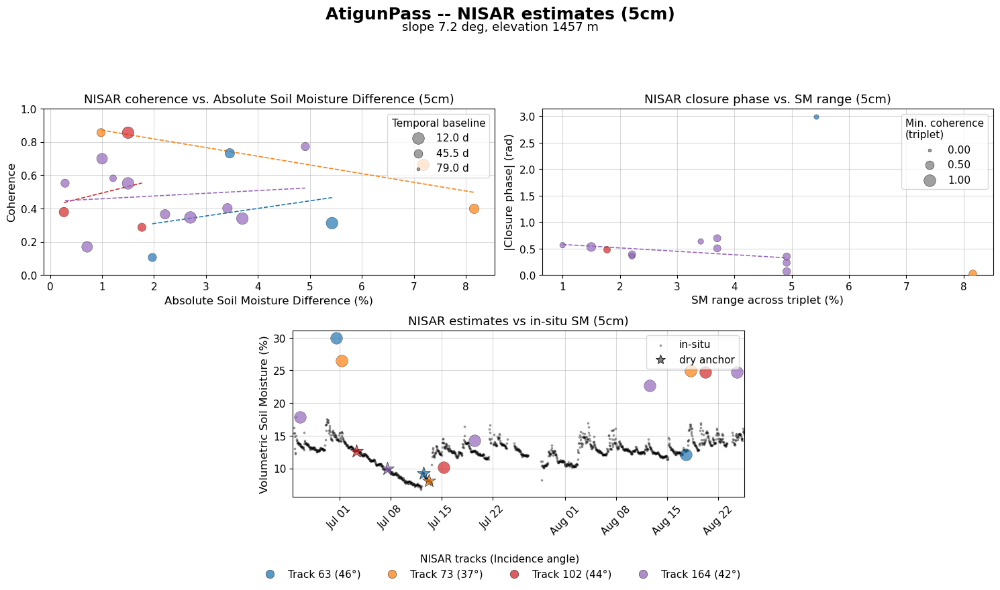

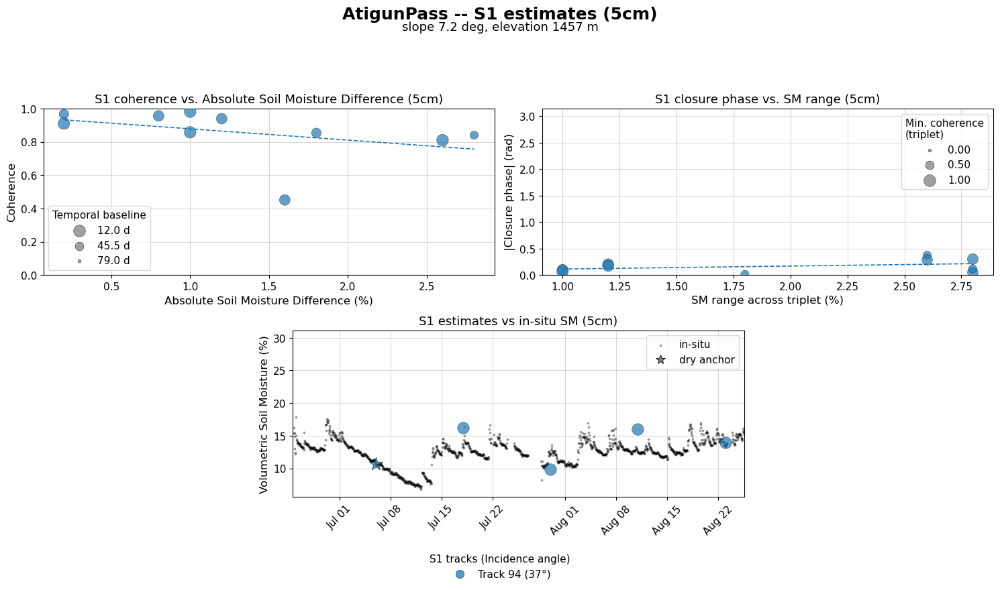

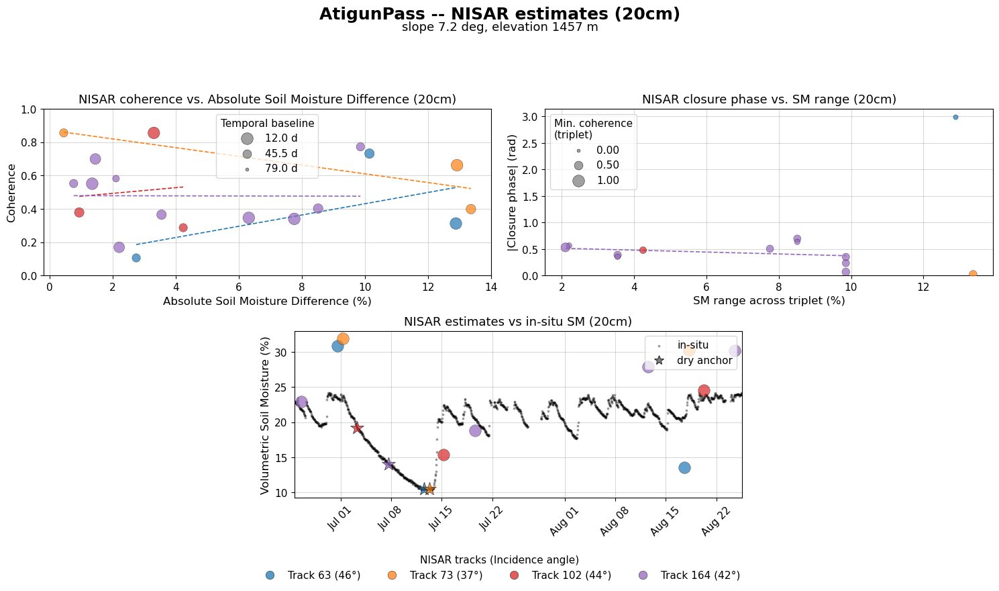

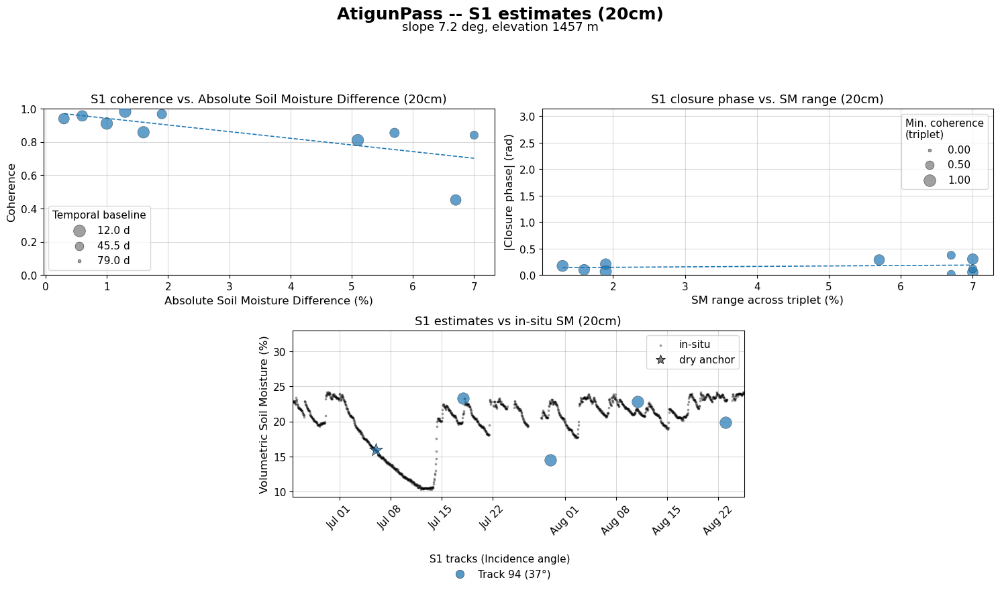

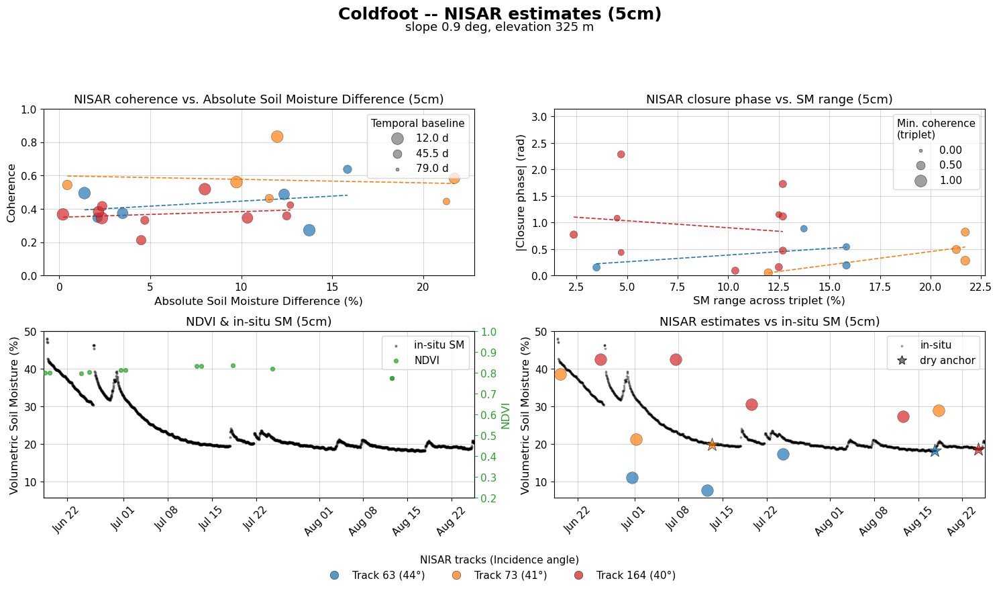

...

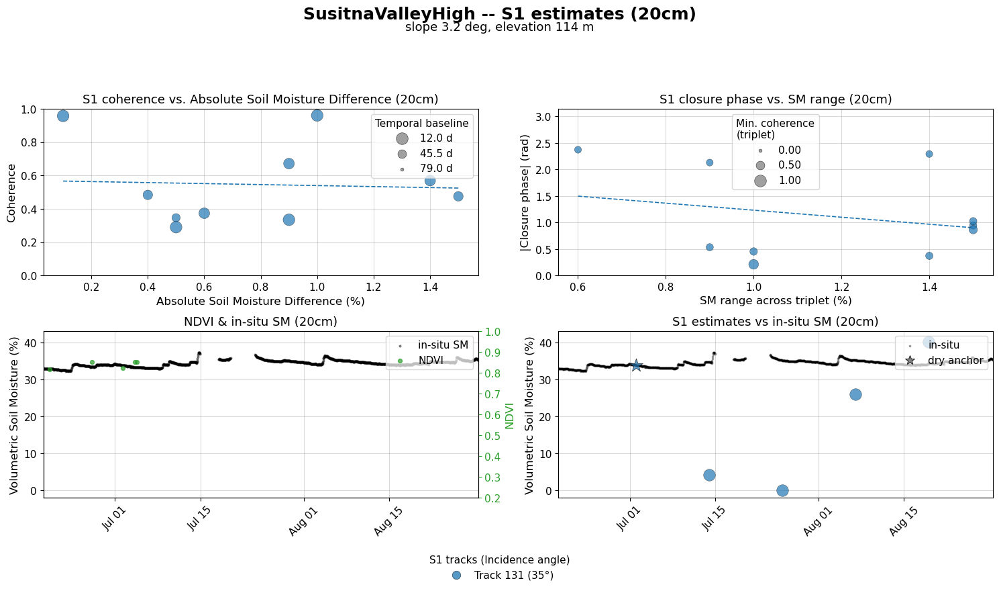

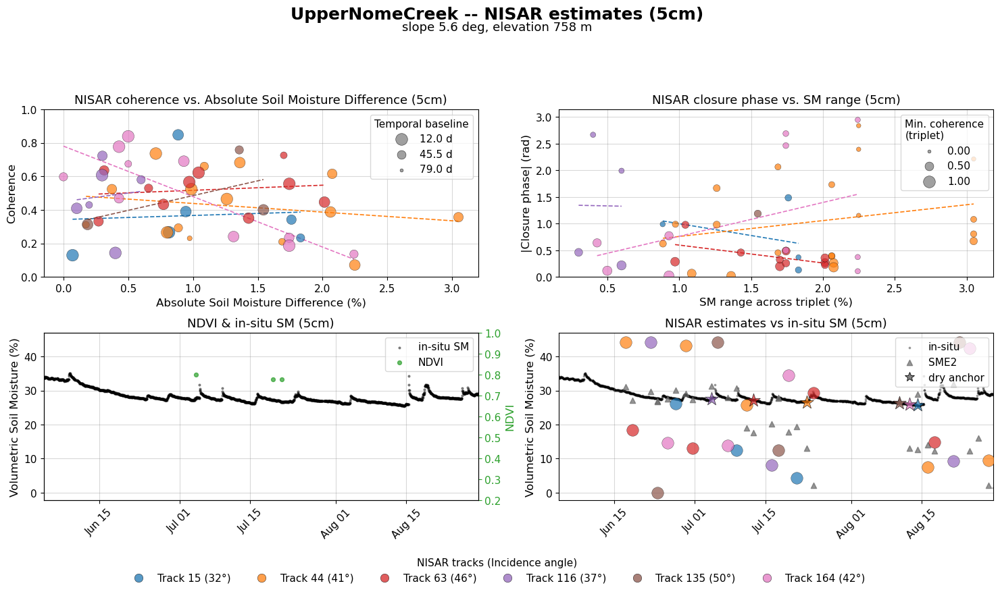

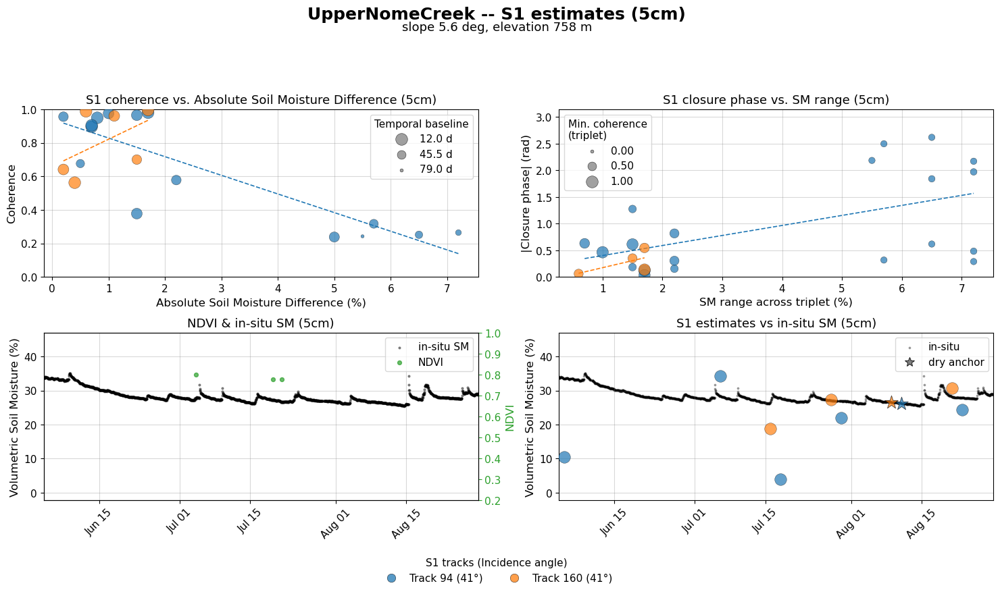

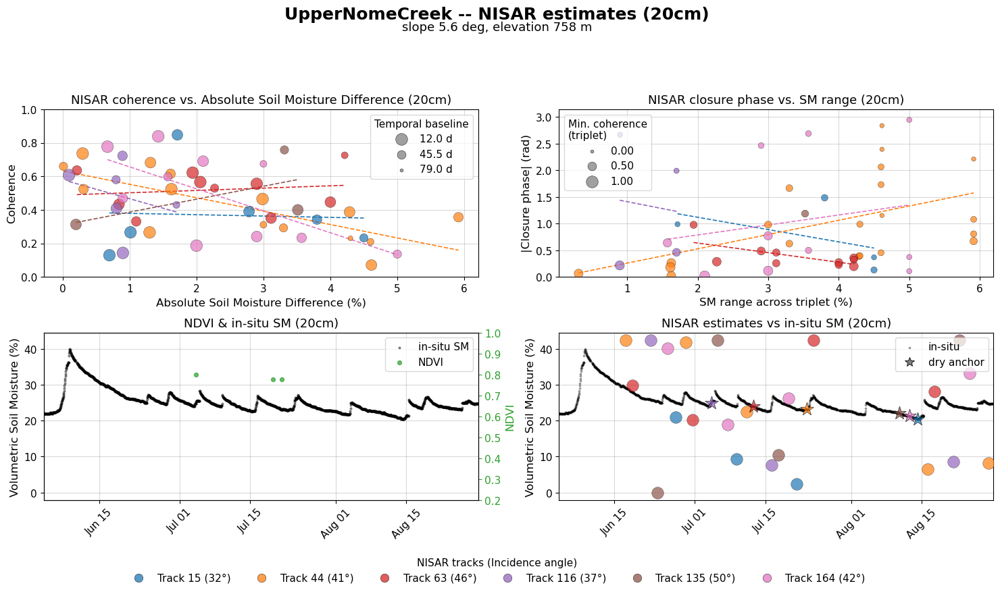

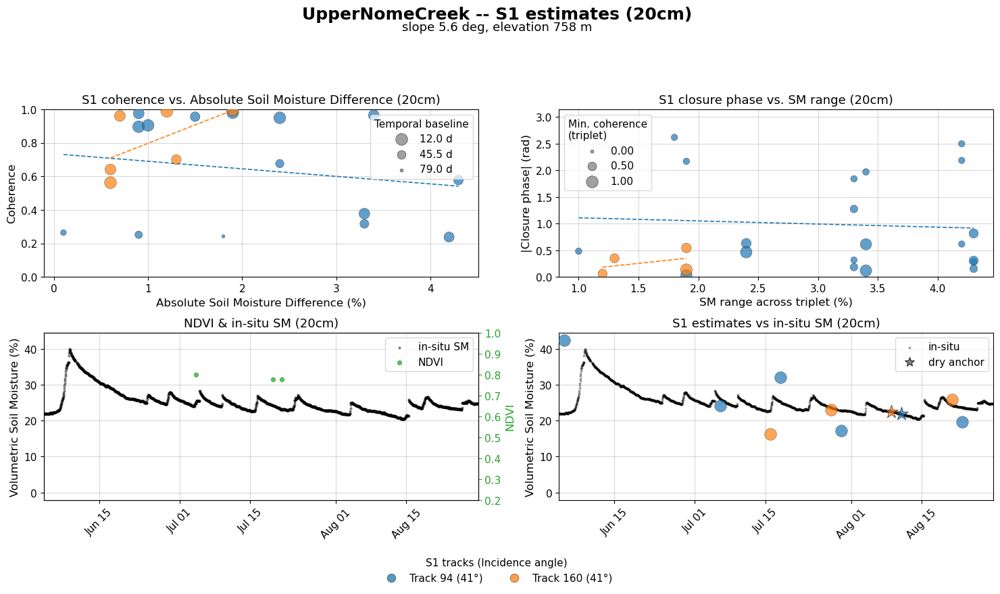

In [17]:
require_globals("stations_to_plot", "slope_by_station", "elevation_by_station",
                 "good_tracks", "good_tracks_20cm")

import matplotlib.gridspec as gridspec

DEPTHS = [("5cm", DEPTH_MAIN, good_tracks), ("20cm", DEPTH_SECONDARY, good_tracks_20cm)]

for station in stations_to_plot:
    slope = slope_by_station.get(station, np.nan)
    elev = elevation_by_station.get(station, np.nan)
    slope_str = f"{slope:.1f} deg" if not np.isnan(slope) else "n/a"
    elev_str = f"{elev:.0f} m" if not np.isnan(elev) else "n/a"

    for depth_label, depth_value, depth_good_tracks in DEPTHS:
        series = read_insitu(station, depth_value)
        if series is None:
            continue
        has_ndvi = read_ndvi(station) is not None
        xlim = compute_station_xlim(station, depth_label, depth_value)

        pages = []  # (fig, ax_ndvi_or_None, ax_ts) -- built for both sensors before either is
                    # shown, so their shared Volumetric Soil Moisture (%) axes can be synced
                    # across the station's NISAR and S1 pages, not just within one page
        for sensor in ["NISAR", "S1"]:
            tracks = _sensor_all_tracks(station, sensor)
            if not tracks:
                continue
            color_map = build_track_color_map(tracks)
            incidence_by_track = _sensor_incidence_by_track(station, sensor)
            page_good_tracks = {t for (s, se, t) in depth_good_tracks if s == station and se == sensor}

            fig = plt.figure(figsize=(15, 9))
            # 2x4: each normal panel is 2 sub-columns wide (0:2 or 2:4), so a lone
            # timeseries panel with no NDVI to share the row can be centered at 1:3 --
            # same width as every other panel, just shifted to the row's middle,
            # rather than stretched to fill the whole row.
            gs = gridspec.GridSpec(2, 4, figure=fig)
            ax_coh, ax_clo = fig.add_subplot(gs[0, 0:2]), fig.add_subplot(gs[0, 2:4])
            if has_ndvi:
                ax_ndvi, ax_ts = fig.add_subplot(gs[1, 0:2]), fig.add_subplot(gs[1, 2:4])
            else:
                ax_ndvi, ax_ts = None, fig.add_subplot(gs[1, 1:3])

            plot_coherence_single(ax_coh, station, series, color_map, sensor, page_good_tracks, depth_label)
            plot_closure_single(ax_clo, station, series, color_map, sensor, page_good_tracks, depth_label)
            if has_ndvi:
                plot_ndvi_insitu(ax_ndvi, station, xlim, depth_label, depth_value)
            plot_estimate_timeseries_single(ax_ts, station, sensor, color_map, xlim, page_good_tracks,
                                             depth_label, depth_value)

            fig.suptitle(f"{station} -- {sensor} estimates ({depth_label})", fontsize=FONT_SUPTITLE,
                         fontweight="bold", y=0.975)
            fig.text(0.5, 0.935, f"slope {slope_str}, elevation {elev_str}",
                     ha="center", fontsize=FONT_PANEL_TITLE, fontweight="normal")
            fig.tight_layout(rect=[0, 0.08, 1, 0.89])

            handles, labels, is_good_list = build_track_legend_handles(
                sensor, color_map, incidence_by_track, page_good_tracks)
            if handles:
                leg = fig.legend(handles, labels, loc="lower center", ncol=min(len(labels), 6),
                                  fontsize=FONT_LEGEND, title=f"{sensor} tracks (Incidence angle)",
                                  title_fontsize=FONT_LEGEND, frameon=False, bbox_to_anchor=(0.5, 0.01))
                for text, is_good in zip(leg.get_texts(), is_good_list):
                    if is_good:
                        text.set_fontweight("bold")

            pages.append((fig, ax_ndvi if has_ndvi else None, ax_ts))

        sm_axes = [ax for _, ax_ndvi, ax_ts in pages for ax in (ax_ndvi, ax_ts)]
        sync_sm_ylim(sm_axes)

        for fig, _ax_ndvi, _ax_ts in pages:
            plt.show()


## 11. Selected-track scatter plots

Three pooled 1:1 scatter plots using **only** points from tracks selected
by Section 9's threshold-bootstrap criteria ("9c") -- across every station
in `stations_to_plot` pooled together, not per-station and not colored by
station (every dot is plain black; overlap is what the transparency is
for). Fonts here are +2pt over the per-station pages' own sizes (Section
0's `FONT_*_SCATTER` constants) -- this is a different, one-off summary
figure, not meant to visually match the per-station pages. Each panel's
annotation box has n (points), the number of contributing tracks/stations,
RMSE, bias, and r (computed the same way as Section 9's RMSE).

1. **Selected NISAR estimates vs. in-situ SM**
2. **Selected S1 estimates vs. in-situ SM**
3. **SME2 vs. in-situ SM** -- not track-restricted (SME2 isn't a per-track
   product, so "selected track" doesn't apply to it); annotated with the
   number of contributing *stations* instead of tracks.

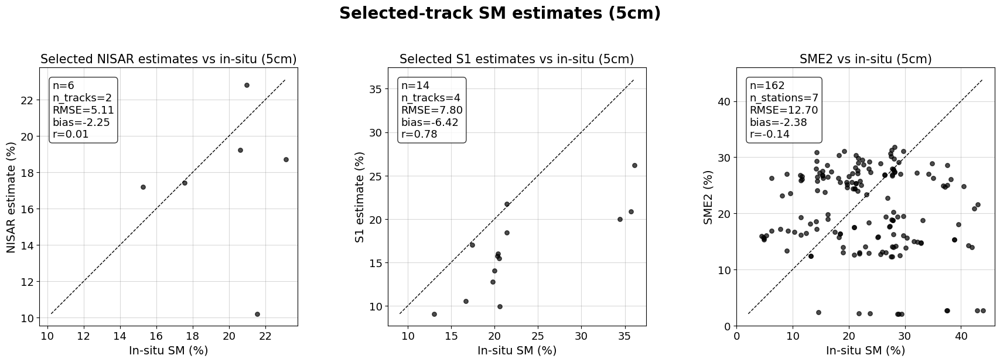

In [18]:
require_globals("stations_to_plot", "good_tracks")


def _pooled_estimates_vs_insitu(sensor, good_tracks_set, depth_label, depth_value):
    """(real_pct, est_pct, n_tracks_used) -- n_tracks_used counts only
    selected tracks that actually contributed >=1 valid point, not every
    track in good_tracks_set for this sensor."""
    id_col = SENSOR_EST_ID_COL[sensor]
    reader = SENSOR_EST_READER[sensor]
    real_out, est_out = [], []
    tracks_used = set()
    for station in stations_to_plot:
        series = read_insitu(station, depth_value)
        if series is None:
            continue
        est = reader(station, depth_label)
        est = est[~est["is_dry_anchor"]]
        if est.empty:
            continue
        for track, g in est.groupby(id_col):
            if (station, sensor, track) not in good_tracks_set:
                continue
            real = np.array([interp_insitu_at(series, ts) for ts in g["date"]]) * 100
            estp = g["sm_pct"].values
            valid = ~np.isnan(real) & ~np.isnan(estp)
            if valid.any():
                tracks_used.add((station, track))
            real_out.append(real[valid])
            est_out.append(estp[valid])
    real_arr = np.concatenate(real_out) if real_out else np.array([])
    est_arr = np.concatenate(est_out) if est_out else np.array([])
    return real_arr, est_arr, len(tracks_used)


def _pooled_sme2_vs_insitu(depth_value):
    """(real_pct, sme2_pct, n_stations_used) -- SME2 isn't per-track, so the
    contributor count is stations, not tracks."""
    real_out, sme2_out = [], []
    stations_used = set()
    for station in stations_to_plot:
        sme2 = read_sme2(station)
        if sme2 is None:
            continue
        series = read_insitu(station, depth_value)
        if series is None:
            continue
        real = np.array([interp_insitu_at(series, ts) for ts in sme2.index]) * 100
        valid = ~np.isnan(real)
        if not valid.any():
            continue
        stations_used.add(station)
        real_out.append(real[valid])
        sme2_out.append(sme2.values[valid])
    real_arr = np.concatenate(real_out) if real_out else np.array([])
    sme2_arr = np.concatenate(sme2_out) if sme2_out else np.array([])
    return real_arr, sme2_arr, len(stations_used)


def _scatter_1to1(ax, x, y, xlabel, ylabel, title, n_label):
    ax.set_xlabel(xlabel, fontsize=FONT_AXIS_LABEL_SCATTER)
    ax.set_ylabel(ylabel, fontsize=FONT_AXIS_LABEL_SCATTER)
    ax.set_title(title, fontsize=FONT_PANEL_TITLE_SCATTER)
    ax.tick_params(axis="both", labelsize=FONT_TICK_SCATTER)
    ax.grid(True, alpha=0.3, linestyle="-", color="gray")
    if len(x) == 0:
        ax.text(0.5, 0.5, "no data", ha="center", va="center", transform=ax.transAxes,
                fontsize=FONT_AXIS_LABEL_SCATTER)
        return
    ax.scatter(x, y, color="black", s=28, alpha=ALPHA_DOTS, zorder=3)
    lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
    ax.plot([lo, hi], [lo, hi], "k--", linewidth=1, zorder=2)
    rmse = np.sqrt(np.mean((y - x) ** 2))
    bias = np.mean(y - x)
    r = np.corrcoef(x, y)[0, 1] if len(x) > 1 and np.std(x) > 0 and np.std(y) > 0 else np.nan
    ax.text(0.05, 0.95, f"n={len(x)}\n{n_label}\nRMSE={rmse:.2f}\nbias={bias:.2f}\nr={r:.2f}",
            transform=ax.transAxes, va="top", fontsize=FONT_LEGEND_SCATTER,
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
    ax.set_aspect("equal", adjustable="box")


def plot_good_track_scatter_figure(depth_label, depth_value, good_tracks_set, suptitle):
    real_n, est_n, n_tracks_n = _pooled_estimates_vs_insitu("NISAR", good_tracks_set, depth_label, depth_value)
    real_s1, est_s1, n_tracks_s1 = _pooled_estimates_vs_insitu("S1", good_tracks_set, depth_label, depth_value)
    real_sme2i, sme2_i, n_stations_sme2 = _pooled_sme2_vs_insitu(depth_value)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    _scatter_1to1(axes[0], real_n, est_n, "In-situ SM (%)", "NISAR estimate (%)",
                  f"Selected NISAR estimates vs in-situ ({depth_label})", f"n_tracks={n_tracks_n}")
    _scatter_1to1(axes[1], real_s1, est_s1, "In-situ SM (%)", "S1 estimate (%)",
                  f"Selected S1 estimates vs in-situ ({depth_label})", f"n_tracks={n_tracks_s1}")
    _scatter_1to1(axes[2], real_sme2i, sme2_i, "In-situ SM (%)", "SME2 (%)",
                  f"SME2 vs in-situ ({depth_label})", f"n_stations={n_stations_sme2}")

    fig.suptitle(suptitle, fontsize=FONT_SUPTITLE_SCATTER, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.90])
    plt.show()


plot_good_track_scatter_figure("5cm", DEPTH_MAIN, good_tracks, "Selected-track SM estimates (5cm)")


## 12. 20cm selected-track scatter plots

Section 11's same 3 pooled scatter plots, at 20cm -- `good_tracks_20cm`
(its own independent threshold-bootstrap selection, computed in Section 9
right alongside the 5cm one, *not* reused from 5cm) plugged into the same
`plot_good_track_scatter_figure` with `depth_label="20cm"`,
`depth_value=DEPTH_SECONDARY`. The 20cm per-station pages themselves are
already in Section 10 (which now outputs both depths) -- this section is
just the 20cm aggregate scatter plots.

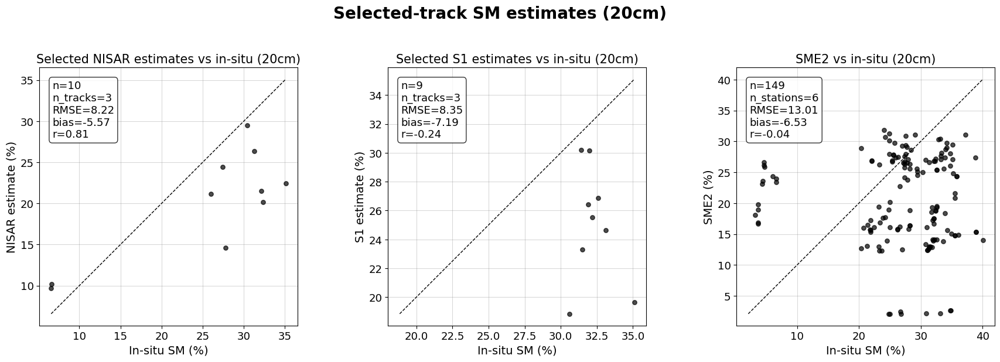

In [19]:
require_globals("plot_good_track_scatter_figure", "good_tracks_20cm")

plot_good_track_scatter_figure("20cm", DEPTH_SECONDARY, good_tracks_20cm, "Selected-track SM estimates (20cm)")


## Summary

`stations_to_plot` (Section 5) requires both a 5cm SM estimate and 5cm
in-situ data -- stations missing either (e.g. TurnagainPass, no in-situ
data at all) are dropped entirely, not just from the per-station pages but
from every stat in Sections 9/11/12 too. Section 9 computes per-(station,
satellite, track) average coherence/\|closure phase\|/RMSE **at both 5cm
and 20cm**, prints the fixed-bar 10a/10b tables for reference at each
depth, then ("9c") derives its own coherence/closure/NDVI thresholds *per
sensor, per depth* from that sensor's own RMSE < 6% tracks and applies
them to every track -- those two final selected sets (`good_tracks`,
`good_tracks_20cm`) drive Section 10's bold-legend/thick-black-outline
highlighting on the per-station pages, which now output **both depths**
(a station with both depths' data produces up to 4 pages: NISAR/S1 x
5cm/20cm). Estimate-timeseries dots are sized to match the biggest
possible coherence/closure-panel dot (`SIZE_MAX`), not their own small
fixed size. NDVI, coherence, and closure-phase axes are fixed (0.2-1, 0-1,
0-pi) for cross-panel comparability, as is scatter-dot size (temporal
baseline in the coherence panel, triplet minimum coherence in the closure
panel, both against a fixed range shared by every page); the NDVI and
estimate-timeseries panels' shared Volumetric Soil Moisture (%) axis is
synced across a station's NISAR and S1 pages too, scoped to one depth at a
time. Every other axis auto-scales to that page's own data. Track colors
are consistent only within one station+satellite page (Section 7), not
across stations or between a station's NISAR and S1 pages. Track identity
and incidence angle live in the shared legend strip below the 2x4 grid
instead of the scatter plots' own legend. Section 11 pools every selected
5cm track's points into 3 plain-black 1:1 scatter plots (selected NISAR vs
in-situ, selected S1 vs in-situ, SME2 vs in-situ -- no per-station
coloring, no NISAR-vs-SME2 panel, annotated with n plus the number of
contributing tracks/stations), fonts 2pt larger than the per-station
pages; Section 12 repeats it for 20cm with `good_tracks_20cm`. Re-run
`NISAR_SM_alaska.ipynb` / `S1_SM_alaska.ipynb` first (their Section 12
export cell) if you want the estimate-timeseries panels and quality
screening to reflect a fresh inversion run.